# Final Winners 96/200 Significance Analysis

This notebook analyzes the final promoted winner runs from the two trainings on 96 and 200 languages
- data is in here:

`outputs/pipeline_runs/moe_study_final_winners_noctua2_a100_4gpu_96_langs_34p5h/moe_study_final_winners_noctua2_a100_4gpu_96_langs_34p5h.xlsx`

`outputs/pipeline_runs/moe_study_final_winners_noctua2_a100_4gpu_200_langs_72h/report.xlsx`


In [2]:
# first we load the data. The Excel report is the single source of trust here
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt

from pathlib import Path
from itertools import combinations
from IPython.display import HTML, display
from scipy.stats import friedmanchisquare, wilcoxon

ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "configs/pipeline").exists() and (path / "outputs/pipeline_runs").exists()
)
REPORTS = {
    "96 languages": ROOT / "outputs/pipeline_runs/moe_study_final_winners_noctua2_a100_4gpu_96_langs_34p5h/moe_study_final_winners_noctua2_a100_4gpu_96_langs_34p5h.xlsx",
    "200 languages": ROOT / "outputs/pipeline_runs/moe_study_final_winners_noctua2_a100_4gpu_200_langs_72h/report.xlsx",
}

loaded = {}
for label, report in REPORTS.items():
    xls = pd.ExcelFile(report)
    raw = pd.read_excel(report, sheet_name="benchmark_raw")
    configs = pd.read_excel(report, sheet_name="run_configs")

    primary = raw[
      ((raw.benchmark == "Belebele") & (raw.metric == "acc_norm")) |
      ((raw.benchmark == "FLORES") & (raw.metric.astype(str).str.startswith("bits_per_byte "))) |
      ((raw.benchmark == "SIB200") & (raw.metric == "acc")) |
      ((raw.benchmark == "Taxi1500") & (raw.metric == "acc"))
    ].copy()
    primary = primary[~primary["is_baseline"].astype(str).str.lower().isin(["true", "1", "yes"])]

    loaded[label] = {
        "report": report,
        "xls": xls,
        "raw": raw,
        "configs": configs,
        "primary": primary,
    }

    print(label)
    print(report)
    print("sheets:", xls.sheet_names)
    print("primary rows:", len(primary), "runs:", primary.run_id.nunique())
    display(HTML(
        '<div style="max-height:500px; overflow:auto; border:1px solid #ccc;">'
        + primary.to_html()
        + '</div>'
    ))

96 languages
/scratch/hpc-prf-merlin/joel/moe-study/outputs/pipeline_runs/moe_study_final_winners_noctua2_a100_4gpu_96_langs_34p5h/moe_study_final_winners_noctua2_a100_4gpu_96_langs_34p5h.xlsx
sheets: ['benchmark_compact', 'data_overview', 'run_configs', 'pipeline_profile', 'benchmark_raw', 'experiment_meta']
primary rows: 549 runs: 3


,run_id,kind,benchmark,task,language,resource_availability,metric,better,value,is_baseline
1,hydralora_r2_heads32,hydralora,Belebele,belebele_als_Latn,als_Latn,LOW,acc_norm,higher,0.487778,False
2,moelora_tr64_e32_k4,moelora,Belebele,belebele_als_Latn,als_Latn,LOW,acc_norm,higher,0.480000,False
3,mola_tr64_e32_k4,mola,Belebele,belebele_als_Latn,als_Latn,LOW,acc_norm,higher,0.463333,False
5,hydralora_r2_heads32,hydralora,Belebele,belebele_arb_Arab,arb_Arab,HIGH,acc_norm,higher,0.594444,False
6,moelora_tr64_e32_k4,moelora,Belebele,belebele_arb_Arab,arb_Arab,HIGH,acc_norm,higher,0.606667,False
7,mola_tr64_e32_k4,mola,Belebele,belebele_arb_Arab,arb_Arab,HIGH,acc_norm,higher,0.578889,False
9,hydralora_r2_heads32,hydralora,Belebele,belebele_arb_Latn,arb_Latn,LOW,acc_norm,higher,0.278889,False
10,moelora_tr64_e32_k4,moelora,Belebele,belebele_arb_Latn,arb_Latn,LOW,acc_norm,higher,0.278889,False
11,mola_tr64_e32_k4,mola,Belebele,belebele_arb_Latn,arb_Latn,LOW,acc_norm,higher,0.280000,False
13,hydralora_r2_heads32,hydralora,Belebele,belebele_azj_Latn,azj_Latn,unknown,acc_norm,higher,0.423333,False


200 languages
/scratch/hpc-prf-merlin/joel/moe-study/outputs/pipeline_runs/moe_study_final_winners_noctua2_a100_4gpu_200_langs_72h/report.xlsx
sheets: ['benchmark_compact', 'data_overview', 'run_configs', 'pipeline_profile', 'benchmark_raw', 'experiment_meta']
primary rows: 918 runs: 3


,run_id,kind,benchmark,task,language,resource_availability,metric,better,value,is_baseline
1,hydralora_r2_heads32,hydralora,Belebele,belebele_als_Latn,als_Latn,LOW,acc_norm,higher,0.487778,False
2,moelora_tr64_e32_k4,moelora,Belebele,belebele_als_Latn,als_Latn,LOW,acc_norm,higher,0.482222,False
3,mola_tr64_e32_k4,mola,Belebele,belebele_als_Latn,als_Latn,LOW,acc_norm,higher,0.455556,False
5,hydralora_r2_heads32,hydralora,Belebele,belebele_amh_Ethi,amh_Ethi,LOW,acc_norm,higher,0.316667,False
6,moelora_tr64_e32_k4,moelora,Belebele,belebele_amh_Ethi,amh_Ethi,LOW,acc_norm,higher,0.323333,False
7,mola_tr64_e32_k4,mola,Belebele,belebele_amh_Ethi,amh_Ethi,LOW,acc_norm,higher,0.314444,False
9,hydralora_r2_heads32,hydralora,Belebele,belebele_arb_Arab,arb_Arab,HIGH,acc_norm,higher,0.583333,False
10,moelora_tr64_e32_k4,moelora,Belebele,belebele_arb_Arab,arb_Arab,HIGH,acc_norm,higher,0.560000,False
11,mola_tr64_e32_k4,mola,Belebele,belebele_arb_Arab,arb_Arab,HIGH,acc_norm,higher,0.565556,False
13,hydralora_r2_heads32,hydralora,Belebele,belebele_arb_Latn,arb_Latn,LOW,acc_norm,higher,0.267778,False


## Prepare Paired Metric Table

We keep only complete runs for the confirmatory comparison. A complete final-winner run has all primary metric rows for its report: 183 rows for the 96-language report and 306 rows for the 200-language report.

In [3]:
# here we prepare our df for analysis and normalize the scores

def parse_total_rank(run_id):
    run_id = str(run_id)
    m = re.search(r"_tr(\d+)_", run_id)
    if m:
        return int(m.group(1))
    m = re.search(r"_r(\d+)(?:_|$)", run_id)
    return int(m.group(1)) if m else np.nan


def parse_component_count(run_id):
    run_id = str(run_id)
    for pat in [r"_e(\d+)(?:_|$)", r"_heads(\d+)$", r"_nup(\d+)$", r"_b(\d+)$"]:
        m = re.search(pat, run_id)
        if m:
            return int(m.group(1))
    return np.nan


def parse_top_k(run_id):
    m = re.search(r"_k(\d+)(?:_|$)", str(run_id))
    return int(m.group(1)) if m else np.nan

analysis_data = {}
for label, data in loaded.items():
    metrics = data["primary"].copy()
    metrics["direction"] = metrics.metric.astype(str).str.extract(r"(en->x|x->en)", expand=False).fillna("")
    metrics["score_family"] = np.where(metrics.benchmark.eq("FLORES"), "FLORES " + metrics.direction, metrics.benchmark)
    metrics["total_rank"] = metrics.run_id.map(parse_total_rank)
    metrics["component_count"] = metrics.run_id.map(parse_component_count)
    metrics["top_k"] = metrics.run_id.map(parse_top_k)
    metrics["value"] = pd.to_numeric(metrics.value, errors="coerce")

    coverage = (
        metrics.groupby(["run_id", "kind"], dropna=False)
        .agg(primary_rows=("value", "count"), score_families=("score_family", "nunique"), tasks=("task", "nunique"))
        .reset_index()
        .sort_values(["primary_rows", "run_id"], ascending=[False, True])
    )
    expected_rows = int(coverage.primary_rows.max())
    complete_runs = coverage.loc[coverage.primary_rows.eq(expected_rows), "run_id"].tolist()
    excluded_runs = coverage.loc[~coverage.primary_rows.eq(expected_rows)].copy()

    metrics = metrics[metrics.run_id.isin(complete_runs)].dropna(subset=["value"]).copy()

    # Min-max normalization within each paired task/metric unit. Higher is always better after this.
    g = metrics.groupby(["score_family", "task", "metric"]).value
    lo, hi = g.transform("min"), g.transform("max")
    metrics["normalized_score"] = np.where(metrics.better.eq("lower"), (hi - metrics.value) / (hi - lo), (metrics.value - lo) / (hi - lo))
    metrics.loc[(hi - lo).eq(0), "normalized_score"] = 1.0

    analysis_data[label] = {
        "metrics": metrics,
        "coverage": coverage,
        "complete_runs": complete_runs,
        "excluded_runs": excluded_runs,
        "expected_rows": expected_rows,
    }

    print(label)
    print("complete runs used:", len(complete_runs), "expected rows per run:", expected_rows)
    print("excluded incomplete runs:", excluded_runs.run_id.tolist())
    display(coverage)

96 languages
complete runs used: 3 expected rows per run: 183
excluded incomplete runs: []


,run_id,kind,primary_rows,score_families,tasks
0,hydralora_r2_heads32,hydralora,183,5,183
1,moelora_tr64_e32_k4,moelora,183,5,183
2,mola_tr64_e32_k4,mola,183,5,183


200 languages
complete runs used: 3 expected rows per run: 306
excluded incomplete runs: []


,run_id,kind,primary_rows,score_families,tasks
0,hydralora_r2_heads32,hydralora,306,5,306
1,moelora_tr64_e32_k4,moelora,306,5,306
2,mola_tr64_e32_k4,mola,306,5,306


## First we look at normalized scores

96 languages
Top configs by mean normalized score


,run_id,kind,total_rank,component_count,top_k,mean_score,n_rows,mean_belebele,mean_flores,mean_sib,mean_taxi
0,mola_tr64_e32_k4,mola,64,32,4.0,0.581288,183,0.250239,0.768498,0.430350,0.544948
1,hydralora_r2_heads32,hydralora,2,32,NaN,0.532573,183,0.434402,0.770518,0.198772,0.219358
2,moelora_tr64_e32_k4,moelora,64,32,4.0,0.467288,183,0.756744,0.114441,0.943918,0.746204


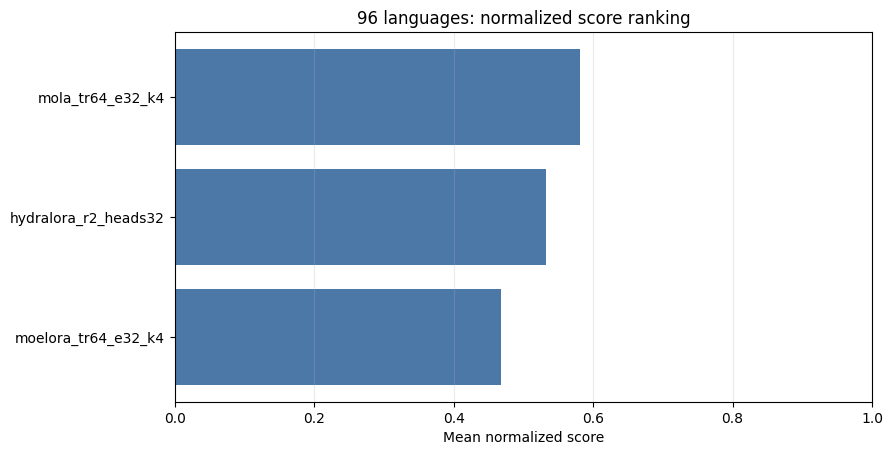

200 languages
Top configs by mean normalized score


,run_id,kind,total_rank,component_count,top_k,mean_score,n_rows,mean_belebele,mean_flores,mean_sib,mean_taxi
0,mola_tr64_e32_k4,mola,64,32,4.0,0.660918,306,0.384414,0.885334,0.623871,0.184903
1,hydralora_r2_heads32,hydralora,2,32,NaN,0.659080,306,0.592395,0.716866,0.445569,0.852315
2,moelora_tr64_e32_k4,moelora,64,32,4.0,0.308647,306,0.563489,0.124398,0.488551,0.418711


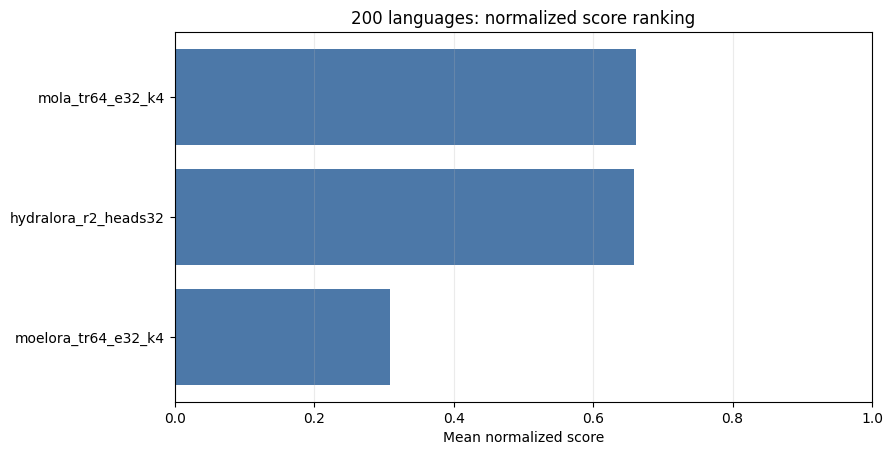

In [4]:
for label, data in analysis_data.items():
    metrics = data["metrics"]
    config_summary = (
        metrics.groupby(["run_id", "kind", "total_rank", "component_count", "top_k"], dropna=False)
        .agg(
            mean_score=("normalized_score", "mean"),
            n_rows=("normalized_score", "count"),
            mean_belebele=("normalized_score", lambda s: s[metrics.loc[s.index, "benchmark"].eq("Belebele")].mean()),
            mean_flores=("normalized_score", lambda s: s[metrics.loc[s.index, "benchmark"].eq("FLORES")].mean()),
            mean_sib=("normalized_score", lambda s: s[metrics.loc[s.index, "benchmark"].eq("SIB200")].mean()),
            mean_taxi=("normalized_score", lambda s: s[metrics.loc[s.index, "benchmark"].eq("Taxi1500")].mean()),
        )
        .sort_values("mean_score", ascending=False)
        .reset_index()
    )
    data["config_summary"] = config_summary

    print(label)
    print("Top configs by mean normalized score")
    display(config_summary.head(10))

    fig, ax = plt.subplots(figsize=(9, 4.8))
    top = config_summary.head(12).iloc[::-1]
    ax.barh(top.run_id, top.mean_score, color="#4C78A8")
    ax.set(xlabel="Mean normalized score", title=f"{label}: normalized score ranking", xlim=(0, 1))
    ax.grid(axis="x", alpha=0.25)
    plt.show()

note: we use the normlaized score as a initial comparison, but to derive the final winners, we use significance analysis which is starting below

---

## Friedman + Holm Significance Tests

- we compare all language X benchmark X approach paris and throw it into the friedmann test to derive the final winners
- we also analyze winning approaches per benchmark
- after applying Friedmann, we apply Wilconxon signed rank between the best two configurations

In [5]:
def holm(pvals):
    pvals = np.asarray(pd.Series(pvals, dtype=float), dtype=float)
    adjusted = np.full(len(pvals), np.nan, dtype=float)
    valid = np.where(np.isfinite(pvals))[0]
    if len(valid) == 0:
        return adjusted
    order = valid[np.argsort(pvals[valid])]
    raw_adj = np.empty(len(order), dtype=float)
    m = len(order)
    for rank, idx in enumerate(order):
        raw_adj[rank] = min((m - rank) * pvals[idx], 1.0)
    raw_adj = np.maximum.accumulate(raw_adj)
    for idx, value in zip(order, raw_adj):
        adjusted[idx] = value
    return adjusted


def config_pivot(df, group_cols):
    return (
        df.groupby(group_cols + ["run_id"])["normalized_score"]
        .mean()
        .unstack("run_id")
        .dropna()
    )


def friedman_configs(df, label, group_cols):
    pivot = config_pivot(df, group_cols)
    configs_order = list(pivot.columns)
    stat, p = friedmanchisquare(*[pivot[c] for c in configs_order])
    avg_ranks = pivot.rank(axis=1, ascending=False).mean().sort_values()
    ordered = avg_ranks.index.tolist()
    return {
        "analysis": label,
        "pivot": pivot,
        "top3_configs": ordered[:3],
        "top4_configs": ordered[:4],
        "n_pairs": len(pivot),
        "n_configs": len(configs_order),
        "friedman_p_raw": p,
        "kendalls_w": stat / (len(pivot) * (pivot.shape[1] - 1)),
        **{f"avg_rank_{c}": avg_ranks.get(c, np.nan) for c in ordered},
    }


def friedman_by_family(df):
    rows = []
    for score_family, g in df.groupby("score_family"):
        result = friedman_configs(g, score_family, ["task", "language", "metric"])
        rows.append({k: v for k, v in result.items() if k != "pivot"})
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["friedman_p_raw"])
    out["significant"] = out["p_holm"] < 0.05
    return out


def wilcoxon_top4(result):
    pivot = result["pivot"]
    top4 = result["top4_configs"]
    rows = []
    # Compare all pairs among top 1-4 in the Friedman order. Direction is higher-ranked > lower-ranked.
    for a, b in combinations(top4, 2):
        w = wilcoxon(pivot[a], pivot[b], zero_method="pratt", alternative="greater")
        rows.append({
            "analysis": result["analysis"],
            "a": a,
            "b": b,
            "mean_a": pivot[a].mean(),
            "mean_b": pivot[b].mean(),
            "median_delta_a_minus_b": (pivot[a] - pivot[b]).median(),
            "n_pairs": len(pivot),
            "p_raw": w.pvalue,
        })
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["p_raw"])
    out["significant"] = out["p_holm"] < 0.05
    return out


for label, data in analysis_data.items():
    metrics = data["metrics"]
    overall = friedman_configs(metrics, "overall", ["score_family", "task", "language", "metric"])
    overall_summary = pd.DataFrame([{k: v for k, v in overall.items() if k != "pivot"}])
    overall_summary["p_holm"] = holm(overall_summary["friedman_p_raw"])
    overall_summary["significant"] = overall_summary["p_holm"] < 0.05

    family_friedman = friedman_by_family(metrics)
    top4_wilcoxon = wilcoxon_top4(overall)

    data["overall"] = overall
    data["overall_summary"] = overall_summary
    data["family_friedman"] = family_friedman
    data["top4_wilcoxon"] = top4_wilcoxon

    print(label)
    print("Overall Friedman result")
    display(overall_summary)
    print("Per-family Friedman results with Holm correction")
    display(family_friedman)
    print("Wilcoxon signed-rank post-hoc among top 1-4 configs with Holm correction")
    display(top4_wilcoxon)

96 languages
Overall Friedman result


,analysis,top3_configs,top4_configs,n_pairs,n_configs,friedman_p_raw,kendalls_w,avg_rank_mola_tr64_e32_k4,avg_rank_hydralora_r2_heads32,avg_rank_moelora_tr64_e32_k4,p_holm,significant
0,overall,"[mola_tr64_e32_k4, hydralora_r2_heads32, moelo...","[mola_tr64_e32_k4, hydralora_r2_heads32, moelo...",183,3,0.12676,0.011287,1.896175,1.997268,2.106557,0.12676,False


Per-family Friedman results with Holm correction


,analysis,top3_configs,top4_configs,n_pairs,n_configs,friedman_p_raw,kendalls_w,avg_rank_moelora_tr64_e32_k4,avg_rank_hydralora_r2_heads32,avg_rank_mola_tr64_e32_k4,p_holm,significant
0,Belebele,"[moelora_tr64_e32_k4, hydralora_r2_heads32, mo...","[moelora_tr64_e32_k4, hydralora_r2_heads32, mo...",34,3,2.292730e-04,0.246488,1.500000,2.014706,2.485294,4.585461e-04,True
1,FLORES en->x,"[mola_tr64_e32_k4, hydralora_r2_heads32, moelo...","[mola_tr64_e32_k4, hydralora_r2_heads32, moelo...",46,3,4.029545e-11,0.520321,2.673913,2.086957,1.239130,1.611818e-10,True
2,FLORES x->en,"[hydralora_r2_heads32, mola_tr64_e32_k4, moelo...","[hydralora_r2_heads32, mola_tr64_e32_k4, moelo...",46,3,2.281677e-13,0.632798,2.826087,1.239130,1.934783,1.140838e-12,True
3,SIB200,"[moelora_tr64_e32_k4, mola_tr64_e32_k4, hydral...","[moelora_tr64_e32_k4, mola_tr64_e32_k4, hydral...",34,3,3.036280e-07,0.441396,1.279412,2.573529,2.147059,9.108839e-07,True
4,Taxi1500,"[moelora_tr64_e32_k4, mola_tr64_e32_k4, hydral...","[moelora_tr64_e32_k4, mola_tr64_e32_k4, hydral...",23,3,1.224743e-02,0.191410,1.652174,2.456522,1.891304,1.224743e-02,True


Wilcoxon signed-rank post-hoc among top 1-4 configs with Holm correction


,analysis,a,b,mean_a,mean_b,median_delta_a_minus_b,n_pairs,p_raw,p_holm,significant
0,overall,mola_tr64_e32_k4,hydralora_r2_heads32,0.581288,0.532573,0.041973,183,0.134357,0.268714,False
1,overall,mola_tr64_e32_k4,moelora_tr64_e32_k4,0.581288,0.467288,0.333333,183,0.036725,0.110176,False
2,overall,hydralora_r2_heads32,moelora_tr64_e32_k4,0.532573,0.467288,0.204679,183,0.154876,0.268714,False


... (2 outputs left out)

Per-family Friedman results with Holm correction


,analysis,top3_configs,top4_configs,n_pairs,n_configs,friedman_p_raw,kendalls_w,avg_rank_hydralora_r2_heads32,avg_rank_moelora_tr64_e32_k4,avg_rank_mola_tr64_e32_k4,p_holm,significant
0,Belebele,"[hydralora_r2_heads32, moelora_tr64_e32_k4, mo...","[hydralora_r2_heads32, moelora_tr64_e32_k4, mo...",57,3,1.377519e-01,0.034777,1.859649,1.929825,2.210526,2.755038e-01,False
1,FLORES en->x,"[mola_tr64_e32_k4, hydralora_r2_heads32, moelo...","[mola_tr64_e32_k4, hydralora_r2_heads32, moelo...",78,3,1.963434e-16,0.463675,1.807692,2.756410,1.435897,9.817168e-16,True
2,FLORES x->en,"[mola_tr64_e32_k4, hydralora_r2_heads32, moelo...","[mola_tr64_e32_k4, hydralora_r2_heads32, moelo...",78,3,1.266417e-14,0.410256,1.794872,2.717949,1.487179,5.065666e-14,True
3,SIB200,"[mola_tr64_e32_k4, moelora_tr64_e32_k4, hydral...","[mola_tr64_e32_k4, moelora_tr64_e32_k4, hydral...",57,3,3.180793e-01,0.020096,2.105263,2.052632,1.842105,3.180793e-01,False
4,Taxi1500,"[hydralora_r2_heads32, moelora_tr64_e32_k4, mo...","[hydralora_r2_heads32, moelora_tr64_e32_k4, mo...",36,3,1.568060e-06,0.371269,1.375000,2.083333,2.541667,4.704179e-06,True


Wilcoxon signed-rank post-hoc among top 1-4 configs with Holm correction


,analysis,a,b,mean_a,mean_b,median_delta_a_minus_b,n_pairs,p_raw,p_holm,significant
0,overall,mola_tr64_e32_k4,hydralora_r2_heads32,0.660918,0.659080,0.017744,306,3.917222e-01,3.917222e-01,False
1,overall,mola_tr64_e32_k4,moelora_tr64_e32_k4,0.660918,0.308647,0.750000,306,2.088669e-13,4.177338e-13,True
2,overall,hydralora_r2_heads32,moelora_tr64_e32_k4,0.659080,0.308647,0.681801,306,9.775340e-14,2.932602e-13,True


### TLDR
- On 96 languages:
  - 1. mola_tr64_e32_k4 
  - 2. hydralora_r2_heads32 
  - 3. moelora_tr64_e32_k4 
- the approaches do not significantly beat one another on 96 languages

- On 200 languages:
  - 1. mola_tr64_e32_k4 
  - 2. hydralora_r2_heads32 
  - 3. moelora_tr64_e32_k4 
- Between 1st and 2nd the difference is not significant, between 2nd and 3rd the differnce is significant